# Notebook 3: Measuring the reliability gap (Setting A and Setting B)

**What we do:** take the outputs saved by notebook 02 and measure *how trustworthy the model's confidence is*,
first on lab images, then on field images, under Setting A and Setting B.

**No training and no GPU here.** We only read a saved file and do arithmetic, so this notebook runs in seconds and
you can change a metric and re-run as often as you like.

### Reusable by design
Every method we test later (AdaBN, DANN, Deep CORAL, JDOT, ...) will save its outputs in the same format as
notebook 02. To evaluate a different method you will only change `METHOD` in Step 1. The metrics are always
computed by the same code, so the comparison is fair.

### Plan
1. Settings
2. Load the saved outputs and line them up with the manifest
3. The metrics, built one at a time (with a tiny example you can check by hand)
4. Temperature scaling
5. Lab reference
6. Setting A
7. Setting B (10 random calibration sets)
8. Reliability diagram
9. Save the results

## Step 1: Settings

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

In [2]:
# ---- Edit these -------------------------------------------------------------
METHOD = "source_only"            # which method's saved outputs to evaluate
TRAIN_SEED = 42                    # the training seed used in notebook 02
OUT_DIR = Path("outputs")
MANIFEST = OUT_DIR / "master_manifest.csv"

N_BINS = 15                       # number of confidence bins for ECE (same as the reference study)
SEEDS = list(range(42, 52))       # the 10 Setting B splits made in notebook 01
HIGH_CONFIDENCE = 0.9             # what we call "highly confident"
MIN_BIN_COUNT = 20                # diagram bars with fewer images than this are drawn faint (too noisy to trust)
# -----------------------------------------------------------------------------

outputs_file = OUT_DIR / f"outputs_{METHOD}_seed{TRAIN_SEED}.npz"
print("Evaluating:", outputs_file)

Evaluating: outputs\outputs_source_only_seed42.npz


## Step 2: Load the saved outputs

The file holds, for each group (`pv_val`, `pv_test`, `pd_known`, `pd_unknown`), the model's **logits** (raw scores,
one per class), the true **labels**, and the image **paths**. (`allow_pickle=True` is needed only because the
paths are stored as text objects. It is our own file, so that's safe.)

In [3]:
saved = np.load(outputs_file, allow_pickle=True)
classes = list(saved["classes"])

# Newer files record how they were made. Older files do not, which is fine.
if "epochs_run" in saved.files:
    print(f"This model was trained for {int(saved['epochs_run'])} epoch(s), debug mode = {bool(saved['debug_mode'])}")
    if bool(saved["debug_mode"]) or int(saved["epochs_run"]) < 5:
        print("*** WARNING: this looks like a quick test run, not the real experiment. ***")
else:
    print("(This file does not record its epoch count. Check the training log in notebook 02.)")

data = {}
for group in ["pv_val", "pv_test", "pd_known"]:
    key = f"{group}_logits"
    data[group] = {"logits": saved[key] if key in saved.files else None,     # None: see the note below
                   "labels": saved[f"{group}_labels"],
                   "paths": saved[f"{group}_paths"]}
    print(f"{group:9s}: {len(data[group]['labels'])} images")

# Two kinds of files exist:
#  * source-only: one set of PlantDoc logits, used for Setting A and for every Setting B split
#  * adapted methods (AdaBN, moment matching, DANN, ...): they adapt using each split's unlabelled calibration
#    images, so they save separate logits per split (pd_known_logits_B_seed42, ...) and have no Setting A
has_setting_A = data["pd_known"]["logits"] is not None
print("Setting A available:", has_setting_A)


def logits_for_seed(seed):
    key = f"pd_known_logits_B_seed{seed}"
    return saved[key] if key in saved.files else data["pd_known"]["logits"]

This model was trained for 20 epoch(s), debug mode = False
pv_val   : 3986 images
pv_test  : 3987 images
pd_known : 2018 images
Setting A available: True


### Line the PlantDoc outputs up with the manifest

Setting B's calibration/test choice lives in the manifest (`B_seed42`, `B_seed43`, ...). We match each saved
output to its manifest row **by image path**, so that we know which outputs are calibration and which are test.

In [4]:
manifest = pd.read_csv(MANIFEST, keep_default_na=False)
b_columns = [f"B_seed{s}" for s in SEEDS]

pd_rows = manifest[(manifest["dataset"] == "pd") & (manifest["role"] == "pd_known")].set_index("path")

# Look up each saved image in the manifest, in the same order as the saved outputs
field_split = pd_rows.loc[data["pd_known"]["paths"], b_columns].reset_index(drop=True)

assert len(field_split) == len(data["pd_known"]["labels"])
print(field_split.iloc[:3])
print()
print("Seed 42 split:", field_split["B_seed42"].value_counts().to_dict())

  B_seed42 B_seed43 B_seed44 B_seed45 B_seed46 B_seed47 B_seed48 B_seed49  \
0     test     test     test     test     test     test     test     test   
1     test     test     test     test     test     test     test     test   
2     test     test     test     test     test     test      cal     test   

  B_seed50 B_seed51  
0     test     test  
1     test     test  
2     test     test  

Seed 42 split: {'test': 1816, 'cal': 202}


## Step 3: The metrics, one at a time

Everything starts from the **probabilities**. The model outputs *logits*; `softmax` turns them into
probabilities that add up to 1. Then for each image:

* **confidence** = the highest probability (how sure the model is)
* **correct** = 1 if the top class is the true class, else 0

A trustworthy model is correct about 80% of the time when it says it is 80% confident.

In [5]:
def softmax(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)    # subtract the max: avoids huge numbers
    exp = np.exp(shifted)
    return exp / exp.sum(axis=1, keepdims=True)


def confidence_and_correct(probs, labels):
    confidence = probs.max(axis=1)                          # the model's top probability
    correct = (probs.argmax(axis=1) == labels).astype(float)
    return confidence, correct

### Expected Calibration Error (ECE)

Idea: sort predictions into confidence bins (0 to 1/15, 1/15 to 2/15, ...). In each bin, compare the **average
confidence** with the **actual accuracy**. ECE is the weighted average of those gaps (weights = share of images
in the bin). **0 is perfect; larger is worse.**

**Overconfidence error (OE)** is similar but counts *only* bins where confidence is higher than accuracy,
weighted by confidence. Those are the bins where a farmer would be misled, so it captures the harmful direction.

In [6]:
def bin_table(confidence, correct, n_bins=N_BINS):
    # For each confidence bin: how many images, their average confidence, their accuracy
    edges = np.linspace(0, 1, n_bins + 1)
    rows = []
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.sum() > 0:
            rows.append((in_bin.sum(), confidence[in_bin].mean(), correct[in_bin].mean()))
    return pd.DataFrame(rows, columns=["count", "avg_confidence", "accuracy"])


def ece(confidence, correct):
    bins = bin_table(confidence, correct)
    weight = bins["count"] / bins["count"].sum()
    return float((weight * (bins["avg_confidence"] - bins["accuracy"]).abs()).sum())


def overconfidence_error(confidence, correct):
    bins = bin_table(confidence, correct)
    weight = bins["count"] / bins["count"].sum()
    too_confident = (bins["avg_confidence"] - bins["accuracy"]).clip(lower=0)   # ignore under-confident bins
    return float((weight * bins["avg_confidence"] * too_confident).sum())

**Check it by hand.** Five predictions: three say 0.9 and two say 0.6. Of the three 0.9s, two are right (accuracy
0.67). Of the two 0.6s, one is right (accuracy 0.50). So:

* the 0.9 bin has a gap of |0.9 - 0.67| = 0.233, weight 3/5
* the 0.6 bin has a gap of |0.6 - 0.50| = 0.100, weight 2/5

ECE = 0.6 x 0.233 + 0.4 x 0.100 = **0.18**. Let's see whether the code agrees.

In [7]:
toy_confidence = np.array([0.9, 0.9, 0.9, 0.6, 0.6])
toy_correct = np.array([1, 1, 0, 1, 0], dtype=float)
print("ECE of the toy example:", round(ece(toy_confidence, toy_correct), 3), "(by hand: 0.180)")

ECE of the toy example: 0.18 (by hand: 0.180)


### The other metrics

* **Brier score**: average squared distance between the predicted probabilities and the true answer
  (a one at the correct class, zeros elsewhere). Lower is better.
* **NLL (negative log-likelihood)**: the penalty for the probability given to the *correct* class. It punishes
  confident mistakes very hard. Lower is better.
* **High-confidence error rate**: among the *wrong* predictions, the share where the model was at least 90% sure.
  This is the "wrong diagnosis, delivered confidently" case from our problem statement.
* **Selective risk at X% coverage**: let the model answer only its X% most confident cases and refuse the rest.
  The *risk* is the error rate among the answered cases. Lower is better. (Here we rank the test images by
  confidence directly. Later we will also ask how well a threshold chosen on calibration data transfers.)

In [8]:
def brier_score(probs, labels):
    one_hot = np.eye(probs.shape[1])[labels]
    return float(((probs - one_hot) ** 2).sum(axis=1).mean())


def nll(probs, labels):
    p_correct = probs[np.arange(len(labels)), labels]
    return float(-np.log(np.clip(p_correct, 1e-12, 1)).mean())


def high_confidence_error_rate(confidence, correct, threshold=HIGH_CONFIDENCE):
    wrong = correct == 0
    if wrong.sum() == 0:
        return 0.0
    return float((confidence[wrong] >= threshold).mean())


def selective_risk(confidence, correct, coverage):
    n_keep = int(round(coverage * len(confidence)))
    most_confident = np.argsort(-confidence)[:n_keep]        # indices of the n_keep most confident images
    return float(1 - correct[most_confident].mean())

### One function that computes everything

`all_metrics` takes logits and labels (and optionally a temperature, see Step 4) and returns every metric in a
dictionary. The **confidence-accuracy gap** (mean confidence minus accuracy) is the plainest summary of the gap:
positive means overconfident.

In [9]:
def all_metrics(logits, labels, temperature=1.0):
    probs = softmax(logits / temperature)
    confidence, correct = confidence_and_correct(probs, labels)
    return {
        "accuracy": correct.mean(),
        "mean_confidence": confidence.mean(),
        "conf_minus_acc": confidence.mean() - correct.mean(),
        "ECE": ece(confidence, correct),
        "OE": overconfidence_error(confidence, correct),
        "Brier": brier_score(probs, labels),
        "NLL": nll(probs, labels),
        "hi_conf_error_rate": high_confidence_error_rate(confidence, correct),
        "risk@80": selective_risk(confidence, correct, 0.80),
        "risk@50": selective_risk(confidence, correct, 0.50),
    }

## Step 4: Temperature scaling

A cheap, standard fix for overconfidence (Guo et al., 2017). We divide all logits by one number **T**:
probabilities = softmax(logits / T). If T > 1 the model becomes less confident, if T < 1 more confident.
T never changes *which* class wins, so **accuracy is unchanged**. Only the confidence moves.

We pick the T that gives the lowest NLL on a **calibration set**. This is exactly why the settings differ:

* **Setting A:** calibration set = PlantVillage validation images (no field labels needed)
* **Setting B:** calibration set = the small labelled PlantDoc sample

In [10]:
def fit_temperature(logits, labels):
    # Find the T that minimises the NLL on the calibration set
    def loss(log_t):
        return nll(softmax(logits / np.exp(log_t)), labels)
    result = minimize_scalar(loss, bounds=(-3, 3), method="bounded")   # search log(T) so T stays positive
    return float(np.exp(result.x))

## Step 5: The lab reference

First, how reliable is the model on the kind of images it was trained on? We use the PlantVillage **test** images
as the lab reference.

In [11]:
lab = all_metrics(data["pv_test"]["logits"], data["pv_test"]["labels"])
pd.Series(lab).round(4)

accuracy              0.9947
mean_confidence       0.9976
conf_minus_acc        0.0028
ECE                   0.0031
OE                    0.0024
Brier                 0.0071
NLL                   0.0152
hi_conf_error_rate    0.2857
risk@80               0.0003
risk@50               0.0000
dtype: float64

## Step 6: Setting A

*(Methods that adapt to target images, like AdaBN or DANN, have no Setting A and skip this step.)*

Test set: **all** known PlantDoc images. No field labels are used anywhere. The temperature is fitted on
PlantVillage validation images. We show the results **before** and **after** temperature scaling.

In [12]:
field_labels = data["pd_known"]["labels"]

if has_setting_A:
    field_logits = data["pd_known"]["logits"]

    # Temperature fitted on PlantVillage validation (source) data only
    T_A = fit_temperature(data["pv_val"]["logits"], data["pv_val"]["labels"])
    print(f"Temperature fitted on PlantVillage validation: T = {T_A:.3f}")

    setting_A = pd.DataFrame({
        "lab (PlantVillage test)": lab,
        "field, raw": all_metrics(field_logits, field_labels),
        "field, temperature-scaled": all_metrics(field_logits, field_labels, temperature=T_A),
    }).T
else:
    print("This method has no Setting A results (it needs target images to adapt). Go to Setting B.")

setting_A.round(4) if has_setting_A else None

Temperature fitted on PlantVillage validation: T = 1.359


,accuracy,mean_confidence,conf_minus_acc,ECE,OE,Brier,NLL,hi_conf_error_rate,risk@80,risk@50
lab (PlantVillage test),0.9947,0.9976,0.0028,0.0031,0.0024,0.0071,0.0152,0.2857,0.0003,0.0000
"field, raw",0.2374,0.8382,0.6008,0.6020,0.5347,1.3149,6.0195,0.5302,0.7540,0.7106
"field, temperature-scaled",0.2374,0.7719,0.5345,0.5378,0.4517,1.2372,4.5845,0.3983,0.7497,0.7076


### The reliability gap, as one number

We defined it as how much *more overconfident* the model is in the field than in the lab:

**RG = (mean confidence - accuracy) in the field  -  (mean confidence - accuracy) in the lab**

In [13]:
if has_setting_A:
    rg_raw = setting_A.loc["field, raw", "conf_minus_acc"] - setting_A.loc["lab (PlantVillage test)", "conf_minus_acc"]
    rg_ts = setting_A.loc["field, temperature-scaled", "conf_minus_acc"] - setting_A.loc["lab (PlantVillage test)", "conf_minus_acc"]
    print(f"Reliability gap (raw):               {rg_raw:.4f}")
    print(f"Reliability gap (temperature-scaled): {rg_ts:.4f}")

Reliability gap (raw):               0.5980
Reliability gap (temperature-scaled): 0.5317


**Questions to think about:**
* Is T close to 1? Why would a temperature fitted on *lab* images do little for *field* images?
* How much of the gap does temperature scaling remove under Setting A?

## Step 7: Setting B

Now we pretend we labelled a small PlantDoc sample (~10%). For each of the 10 splits from notebook 01:

1. Take the **calibration** images and fit a temperature on them.
2. Evaluate on the **test** images only (calibration images are never used for judging).

Repeating over 10 splits shows how much the result depends on *which* images happened to be labelled.
Let's look at one split first.

In [14]:
seed = 42
is_cal = (field_split[f"B_seed{seed}"] == "cal").to_numpy()
is_test = ~is_cal
seed_logits = logits_for_seed(seed)

T_B = fit_temperature(seed_logits[is_cal], field_labels[is_cal])
print(f"Seed {seed}: {is_cal.sum()} calibration images, {is_test.sum()} test images, T = {T_B:.3f}")

pd.DataFrame({
    "field test, raw": all_metrics(seed_logits[is_test], field_labels[is_test]),
    "field test, temperature-scaled": all_metrics(seed_logits[is_test], field_labels[is_test], temperature=T_B),
}).T.round(4)

Seed 42: 202 calibration images, 1816 test images, T = 5.022


,accuracy,mean_confidence,conf_minus_acc,ECE,OE,Brier,NLL,hi_conf_error_rate,risk@80,risk@50
"field test, raw",0.239,0.8367,0.5978,0.5992,0.5319,1.3117,6.0148,0.5282,0.7515,0.7115
"field test, temperature-scaled",0.239,0.2590,0.0200,0.0462,0.0143,0.8905,2.6117,0.0000,0.7426,0.7093


Now all 10 splits. Each row of `runs_B` is one split.

In [15]:
runs_B = []
for seed in SEEDS:
    is_cal = (field_split[f"B_seed{seed}"] == "cal").to_numpy()
    is_test = ~is_cal
    seed_logits = logits_for_seed(seed)
    T = fit_temperature(seed_logits[is_cal], field_labels[is_cal])

    for label, temperature in [("raw", 1.0), ("temperature-scaled", T)]:
        row = all_metrics(seed_logits[is_test], field_labels[is_test], temperature=temperature)
        row.update({"split_seed": seed, "version": label, "T": temperature, "n_test": int(is_test.sum())})
        runs_B.append(row)

runs_B = pd.DataFrame(runs_B)
runs_B.head(4).round(4)

,accuracy,mean_confidence,conf_minus_acc,ECE,OE,Brier,NLL,hi_conf_error_rate,risk@80,risk@50,split_seed,version,T,n_test
0,0.2390,0.8367,0.5978,0.5992,0.5319,1.3117,6.0148,0.5282,0.7515,0.7115,42,raw,1.0000,1816
1,0.2390,0.2590,0.0200,0.0462,0.0143,0.8905,2.6117,0.0000,0.7426,0.7093,42,temperature-scaled,5.0218,1816
2,0.2384,0.8392,0.6008,0.6025,0.5354,1.3144,6.0226,0.5307,0.7536,0.7081,43,raw,1.0000,1816
3,0.2384,0.2605,0.0221,0.0443,0.0140,0.8900,2.6113,0.0000,0.7447,0.7037,43,temperature-scaled,5.0058,1816


In [16]:
# Mean and standard deviation across the 10 splits
metric_columns = ["accuracy", "mean_confidence", "conf_minus_acc", "ECE", "OE", "Brier", "NLL",
                  "hi_conf_error_rate", "risk@80", "risk@50", "T"]
summary_B = runs_B.groupby("version")[metric_columns].agg(["mean", "std"]).round(4)
summary_B.T

version                     raw  temperature-scaled
accuracy           mean  0.2376              0.2376
                   std   0.0023              0.0023
mean_confidence    mean  0.8379              0.2583
                   std   0.0013              0.0147
conf_minus_acc     mean  0.6003              0.0207
                   std   0.0026              0.0163
ECE                mean  0.6014              0.0440
                   std   0.0022              0.0090
OE                 mean  0.5343              0.0139
                   std   0.0024              0.0054
Brier              mean  1.3142              0.8902
                   std   0.0040              0.0021
NLL                mean  6.0135              2.6121
                   std   0.0267              0.0037
hi_conf_error_rate mean  0.5294              0.0000
                   std   0.0035              0.0000
risk@80            mean  0.7539              0.7447
                   std   0.0025              0.0034
risk@50            mean  0.7102              0.7084
                   std   0.0035              0.0036
T                  mean  1.0000              5.0462
                   std   0.0000              0.2322

**Questions to think about:**
* Is the standard deviation across splits small compared with the differences between raw and scaled?
* How does the temperature fitted on field labels (Setting B) compare with the one fitted on lab images (A)?
* After scaling, is the model *well calibrated* in the field (ECE near 0), or only *better*?
* Look at `risk@80`: even when the model answers only its 80% most confident cases, how often is it still wrong?

## Step 8: Reliability diagram

The classic picture of calibration. For each confidence bin, the bar shows the **actual accuracy**. A perfectly
calibrated model follows the dotted diagonal (80% confident means right 80% of the time). Bars far *below* the
diagonal mean overconfidence.

**How to read this version:** the small number above each bar is how many images fall in that bin. Bars with fewer than
`MIN_BIN_COUNT` images are drawn faint, because their height is mostly luck (for example, one wrong image in a bin of
three makes the bar drop by a third). The title shows the ECE, the count-weighted summary. A bar can sit far from the
diagonal and still barely matter if it holds a handful of images, so always read the counts together with the heights.


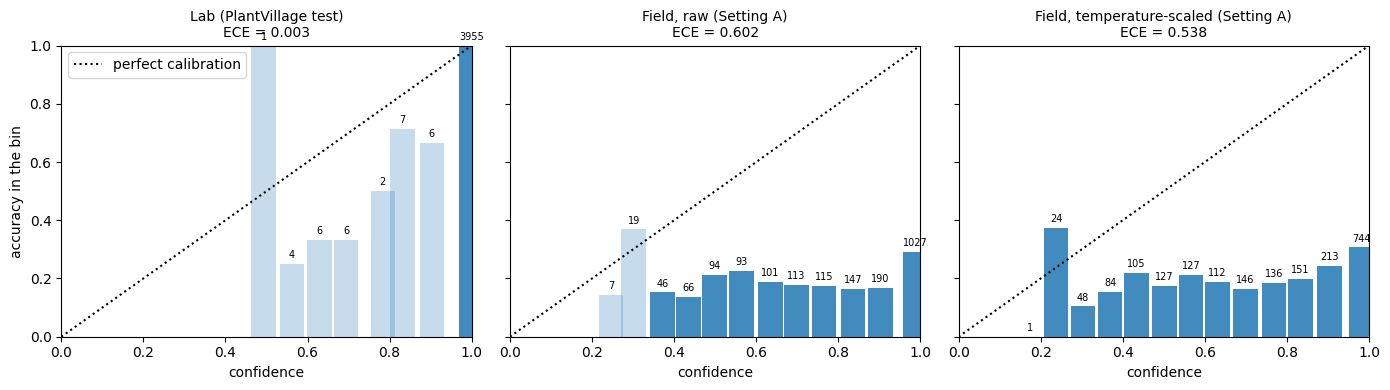

In [17]:
def reliability_panel(ax, confidence, correct, title):
    bins = bin_table(confidence, correct)
    for _, row in bins.iterrows():
        solid = row["count"] >= MIN_BIN_COUNT
        ax.bar(row["avg_confidence"], row["accuracy"], width=1 / N_BINS * 0.9, color="C0", alpha=0.85 if solid else 0.25)
        ax.text(row["avg_confidence"], row["accuracy"] + 0.02, str(int(row["count"])), ha="center", fontsize=7)
    ax.plot([0, 1], [0, 1], "k:", label="perfect calibration")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("confidence")
    ax.set_title(title + "\nECE = " + format(ece(confidence, correct), ".3f"), fontsize=10)


# Which field results to draw: Setting A if the method has it, otherwise the test images of the first Setting B split
if has_setting_A:
    shown_logits, shown_labels, shown_T, shown_name = field_logits, field_labels, T_A, "Setting A"
else:
    first = SEEDS[0]
    cal_mask = (field_split[f"B_seed{first}"] == "cal").to_numpy()
    all_logits_first = logits_for_seed(first)
    shown_logits, shown_labels = all_logits_first[~cal_mask], field_labels[~cal_mask]
    shown_T = fit_temperature(all_logits_first[cal_mask], field_labels[cal_mask])
    shown_name = f"Setting B, split {first}"

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

p_lab = softmax(data["pv_test"]["logits"])
reliability_panel(axes[0], *confidence_and_correct(p_lab, data["pv_test"]["labels"]), "Lab (PlantVillage test)")

p_raw = softmax(shown_logits)
reliability_panel(axes[1], *confidence_and_correct(p_raw, shown_labels), f"Field, raw ({shown_name})")

p_ts = softmax(shown_logits / shown_T)
reliability_panel(axes[2], *confidence_and_correct(p_ts, shown_labels), f"Field, temperature-scaled ({shown_name})")

axes[0].set_ylabel("accuracy in the bin")
axes[0].legend()
plt.tight_layout()
plt.show()

## Step 9: Save the results

One long table, so later notebooks can stack the tables of different methods and compare them.

In [18]:
rows = []

# Setting A (only methods that have it)
if has_setting_A:
    for label, temperature in [("raw", 1.0), ("temperature-scaled", T_A)]:
        row = all_metrics(field_logits, field_labels, temperature=temperature)
        row.update({"setting": "A", "split_seed": np.nan, "version": label, "T": temperature, "n_test": len(field_labels)})
        rows.append(row)

parts = [runs_B.assign(setting="B")]
if rows:
    parts.insert(0, pd.DataFrame(rows))
results = pd.concat(parts, ignore_index=True)
results.insert(0, "method", METHOD)
results.insert(1, "train_seed", TRAIN_SEED)

results_file = OUT_DIR / f"metrics_{METHOD}_seed{TRAIN_SEED}.csv"
results.to_csv(results_file, index=False)
print("Saved", results_file, f"({len(results)} rows)")

Saved outputs\metrics_source_only_seed42.csv (22 rows)


## What we learned and what comes next

You now have, for the source-only model, the full reliability picture under both settings: the lab reference, the
raw field results, and the temperature-scaled results (with the Setting B spread over 10 splits).

**Compare with the reference study** (representative values; yours will differ a little): Setting A raw ECE about
0.477 and Setting B calibrated ECE about 0.365, with risk@80 around 0.64. If you are in that region, the baseline
is reproduced.

**Next notebook (04):** the three lightweight baselines from the reference study, **AdaBN**, **feature moment
matching** and **DANN**. Each will save its outputs in this same format, and we will re-run *this* notebook by
changing only `METHOD`.